In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [24]:
#### INPUT PATH
INPUT_FOLDER = 'tris\\force_dist_v4'
K05_path = os.path.join(INPUT_FOLDER, 'K_005\\obs.dat')
K15_path = os.path.join(INPUT_FOLDER, 'K_015\\obs.dat')
K25_path = os.path.join(INPUT_FOLDER, 'K_025\\obs.dat')
K15_r0_2_path = os.path.join(INPUT_FOLDER, 'K_015_r0_2\\obs.dat')

#### LOAD DATA INTO DATAFRAMES
K05_r0_4_df = pd.read_csv(K05_path, 
                     delim_whitespace=True, 
                     header=None,
                     names=['step','dist','force_mag'])
K15_r0_4_df = pd.read_csv(K15_path, 
                     delim_whitespace=True, 
                     header=None,
                     names=['step','dist','force_mag'])
K25_r0_4_df = pd.read_csv(K25_path, 
                     delim_whitespace=True, 
                     header=None,
                     names=['step','dist','force_mag'])
K15_r0_2_df = pd.read_csv(K15_r0_2_path, 
                     delim_whitespace=True, 
                     header=None,
                     names=['step','dist','force_mag'])

C:\Users\Tristan\AppData\Local\Temp\ipykernel_40152\2378468989.py:9: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  K05_r0_4_df = pd.read_csv(K05_path,
C:\Users\Tristan\AppData\Local\Temp\ipykernel_40152\2378468989.py:13: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  K15_r0_4_df = pd.read_csv(K15_path,
C:\Users\Tristan\AppData\Local\Temp\ipykernel_40152\2378468989.py:17: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  K25_r0_4_df = pd.read_csv(K25_path,
C:\Users\Tristan\AppData\Local\Temp\ipykernel_40152\2378468989.py:21: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  K15_r0_2_df = pd.read_csv(K15_r0_2_pa

In [37]:
#### FILTER DATA
from functions import *

WINDOW_SIZE = 1  # Adjust to control smoothing
K05_r0_4_df_filtered = moving_average_filter(K05_r0_4_df, 
                                         window_size=WINDOW_SIZE, 
                                         epoch_col='step', 
                                         filter_cols='force_mag')
K15_r0_4_df_filtered = moving_average_filter(K15_r0_4_df, 
                                         window_size=WINDOW_SIZE, 
                                         epoch_col='step', 
                                         filter_cols='force_mag')
K25_r0_4_df_filtered = moving_average_filter(K25_r0_4_df, 
                                         window_size=WINDOW_SIZE, 
                                         epoch_col='step', 
                                         filter_cols='force_mag')
K15_r0_2_df_filtered = moving_average_filter(K15_r0_2_df, 
                                         window_size=WINDOW_SIZE, 
                                         epoch_col='step', 
                                         filter_cols='force_mag')

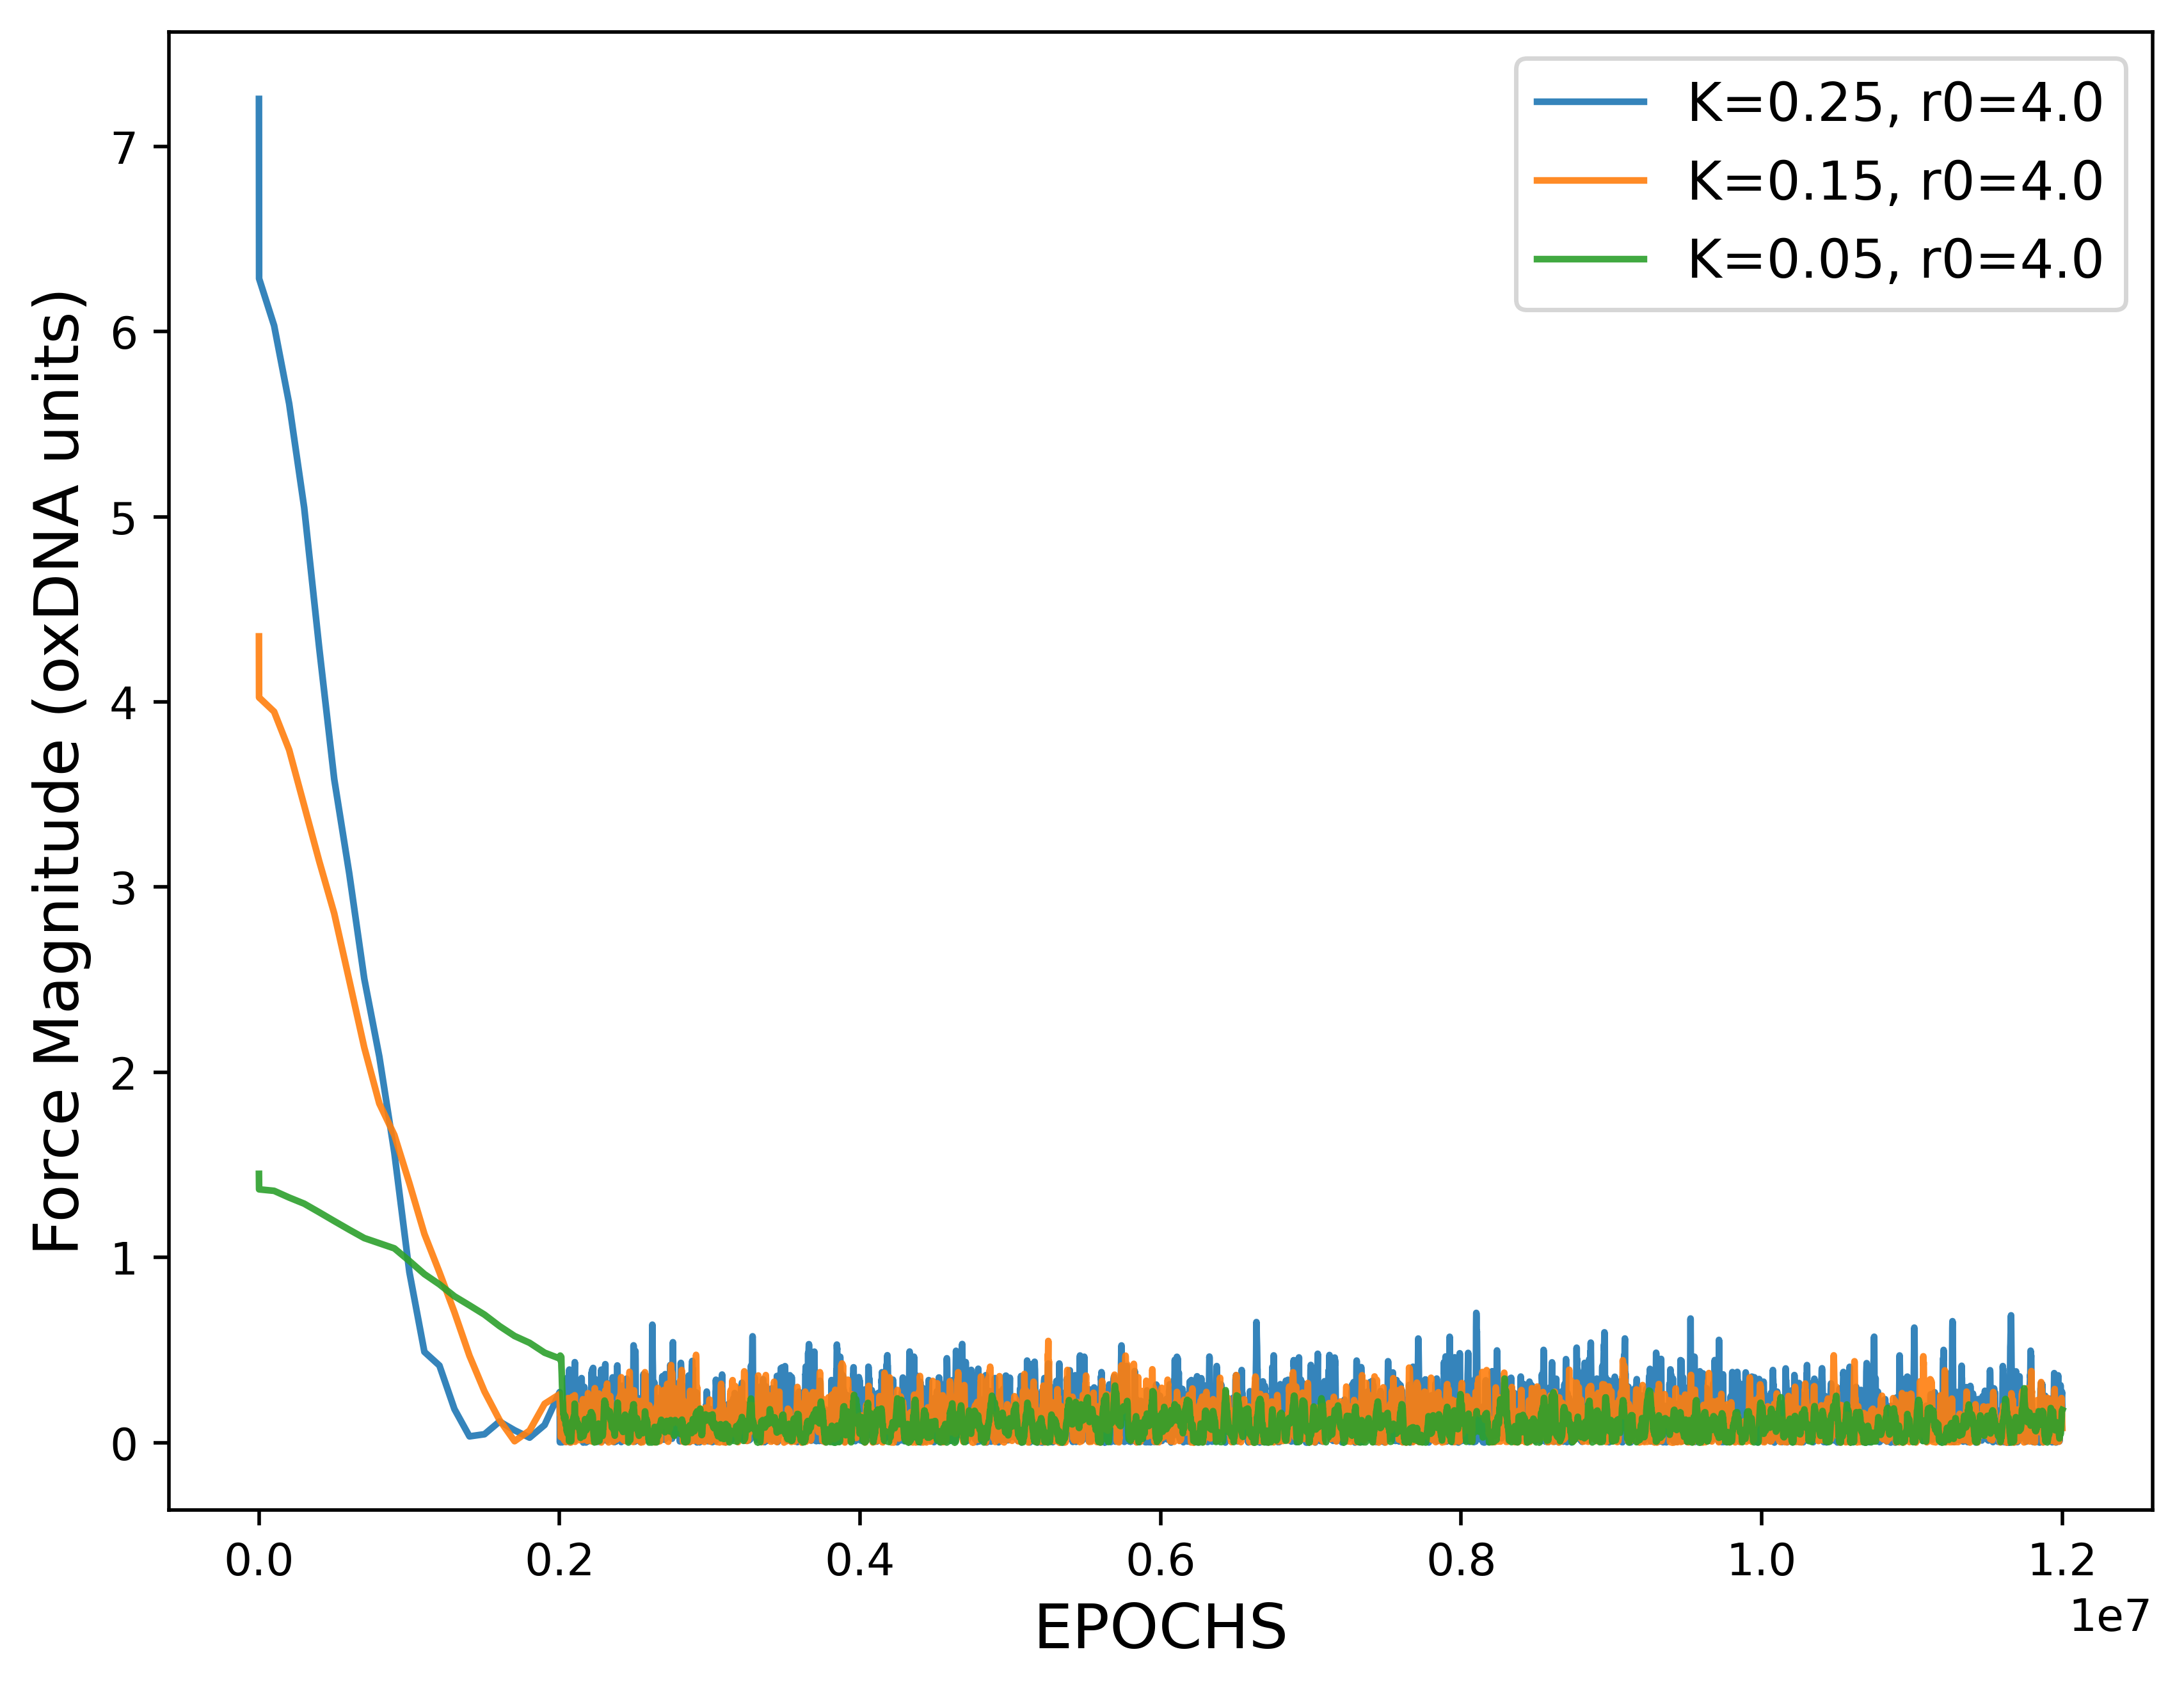

In [29]:
#### PLOT SIGNALS
fig, ax = plt.subplots(figsize=(8,6), dpi=500)
ax.plot(K25_r0_4_df_filtered['step'], 
        K25_r0_4_df_filtered['force_mag_filtered'], 
        alpha=0.9, linewidth=1.5, label='K=0.25, r0=4.0')
ax.plot(K15_r0_4_df_filtered['step'], 
        K15_r0_4_df_filtered['force_mag_filtered'], 
        alpha=0.9, linewidth=1.5, label='K=0.15, r0=4.0')
ax.plot(K05_r0_4_df_filtered['step'], 
        K05_r0_4_df_filtered['force_mag_filtered'],
        alpha=0.9, linewidth=1.5, label='K=0.05, r0=4.0')
ax.set_xlabel('EPOCHS', fontsize=14)
ax.set_ylabel('Force Magnitude (oxDNA units)', fontsize=14)
ax.legend(fontsize=12)

In [32]:
#### APPLY CUTOFF
CUTOFF = 0.20e7  # 2,000,000 steps
K05_r0_4_df_cfiltered = K05_r0_4_df_filtered[K05_r0_4_df_filtered['step'] >= CUTOFF].reset_index(drop=True)
K15_r0_4_df_cfiltered = K15_r0_4_df_filtered[K15_r0_4_df_filtered['step'] >= CUTOFF].reset_index(drop=True)
K25_r0_4_df_cfiltered = K25_r0_4_df_filtered[K25_r0_4_df_filtered['step'] >= CUTOFF].reset_index(drop=True)

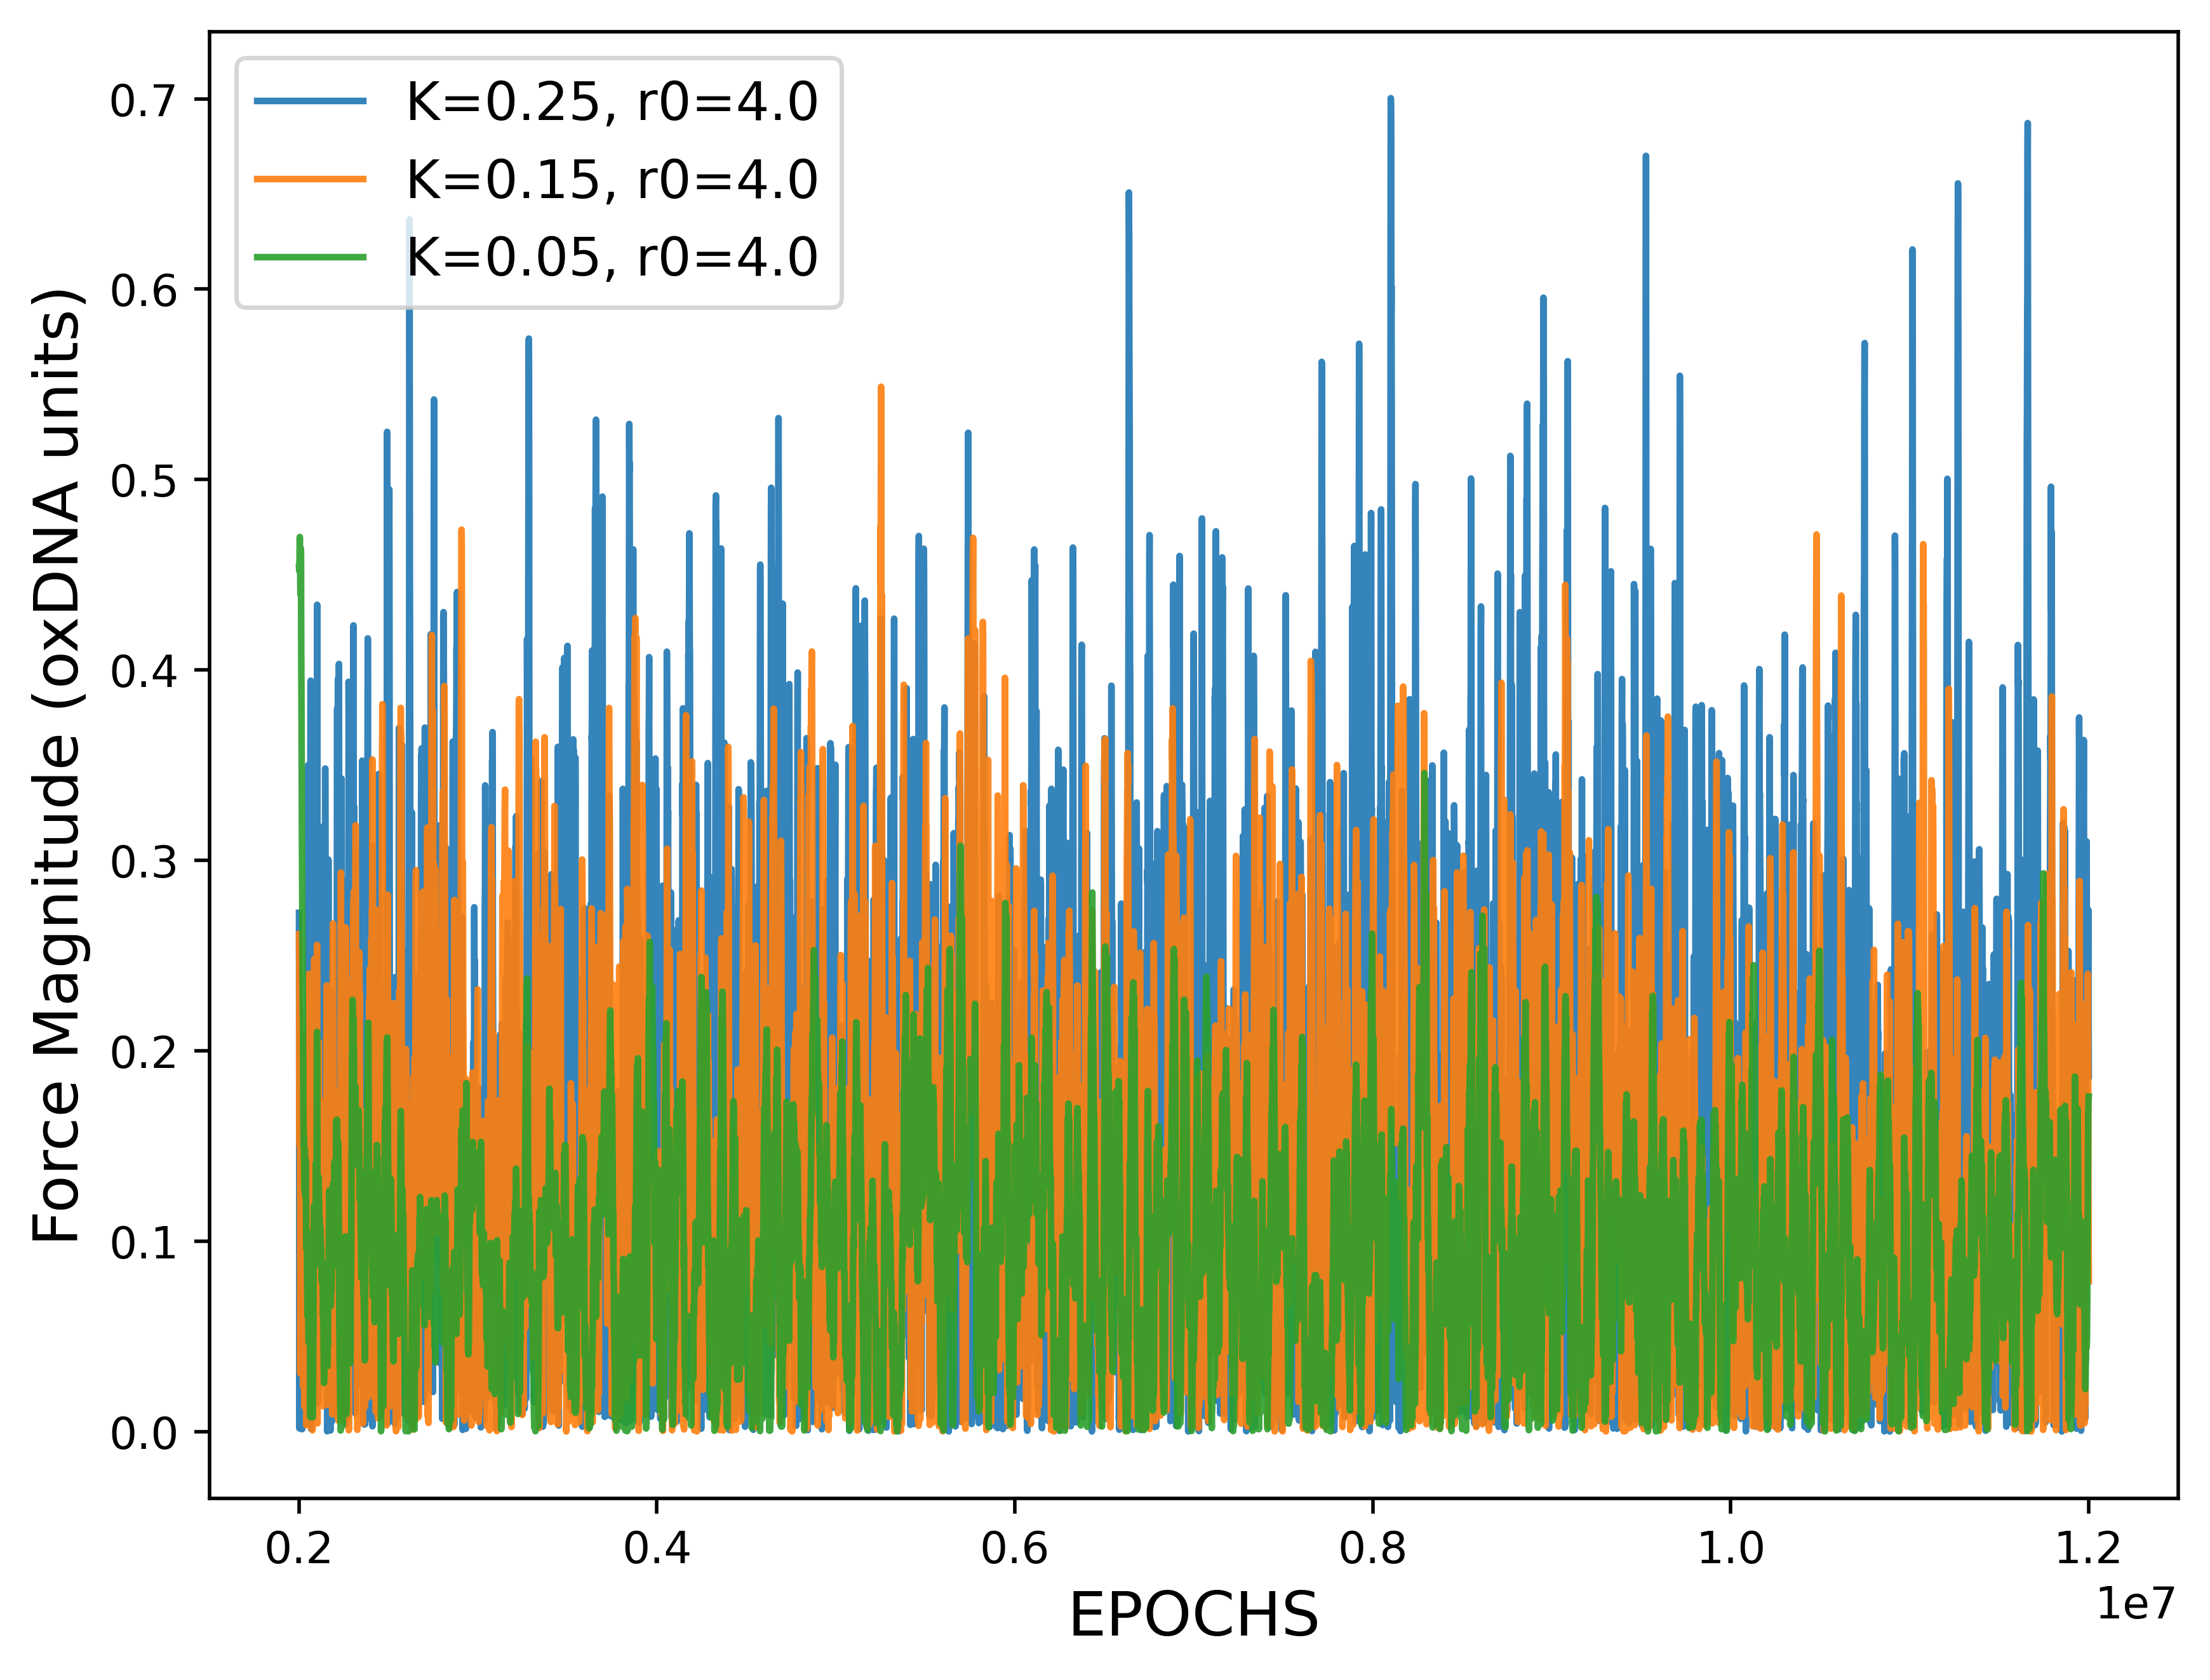

In [33]:
#### PLOT SIGNALS AFTER CUTOFF
fig, ax = plt.subplots(figsize=(8,6), dpi=500)
ax.plot(K25_r0_4_df_cfiltered['step'], 
        K25_r0_4_df_cfiltered['force_mag_filtered'], 
        alpha=0.9, linewidth=1.5, label='K=0.25, r0=4.0')
ax.plot(K15_r0_4_df_cfiltered['step'], 
        K15_r0_4_df_cfiltered['force_mag_filtered'], 
        alpha=0.9, linewidth=1.5, label='K=0.15, r0=4.0')
ax.plot(K05_r0_4_df_cfiltered['step'], 
        K05_r0_4_df_cfiltered['force_mag_filtered'], 
        alpha=0.9, linewidth=1.5, label='K=0.05, r0=4.0')
ax.set_xlabel('EPOCHS', fontsize=14)
ax.set_ylabel('Force Magnitude (oxDNA units)', fontsize=14)
ax.legend(fontsize=12)

In [34]:
#### BASIC STATISTICS OF STEADY STATE REGION
print("K25_r0_4_df_filtered:",
    "mean", np.mean(K25_r0_4_df_cfiltered['force_mag_filtered']),
    "std", np.std(K25_r0_4_df_cfiltered['force_mag_filtered']))
print("K15_r0_4_df_filtered:",
      "mean", np.mean(K15_r0_4_df_cfiltered['force_mag_filtered']),
      "std", np.std(K15_r0_4_df_cfiltered['force_mag_filtered']))
print("K05_r0_4_df_filtered:",
      "mean", np.mean(K05_r0_4_df_cfiltered['force_mag_filtered']),
      "std", np.std(K05_r0_4_df_cfiltered['force_mag_filtered']))

K25_r0_4_df_filtered: mean 0.1532529522355029 std 0.11246588731803825
K15_r0_4_df_filtered: mean 0.12760850829358128 std 0.08812096468635684
K05_r0_4_df_filtered: mean 0.09380455448666267 std 0.06045195066606016


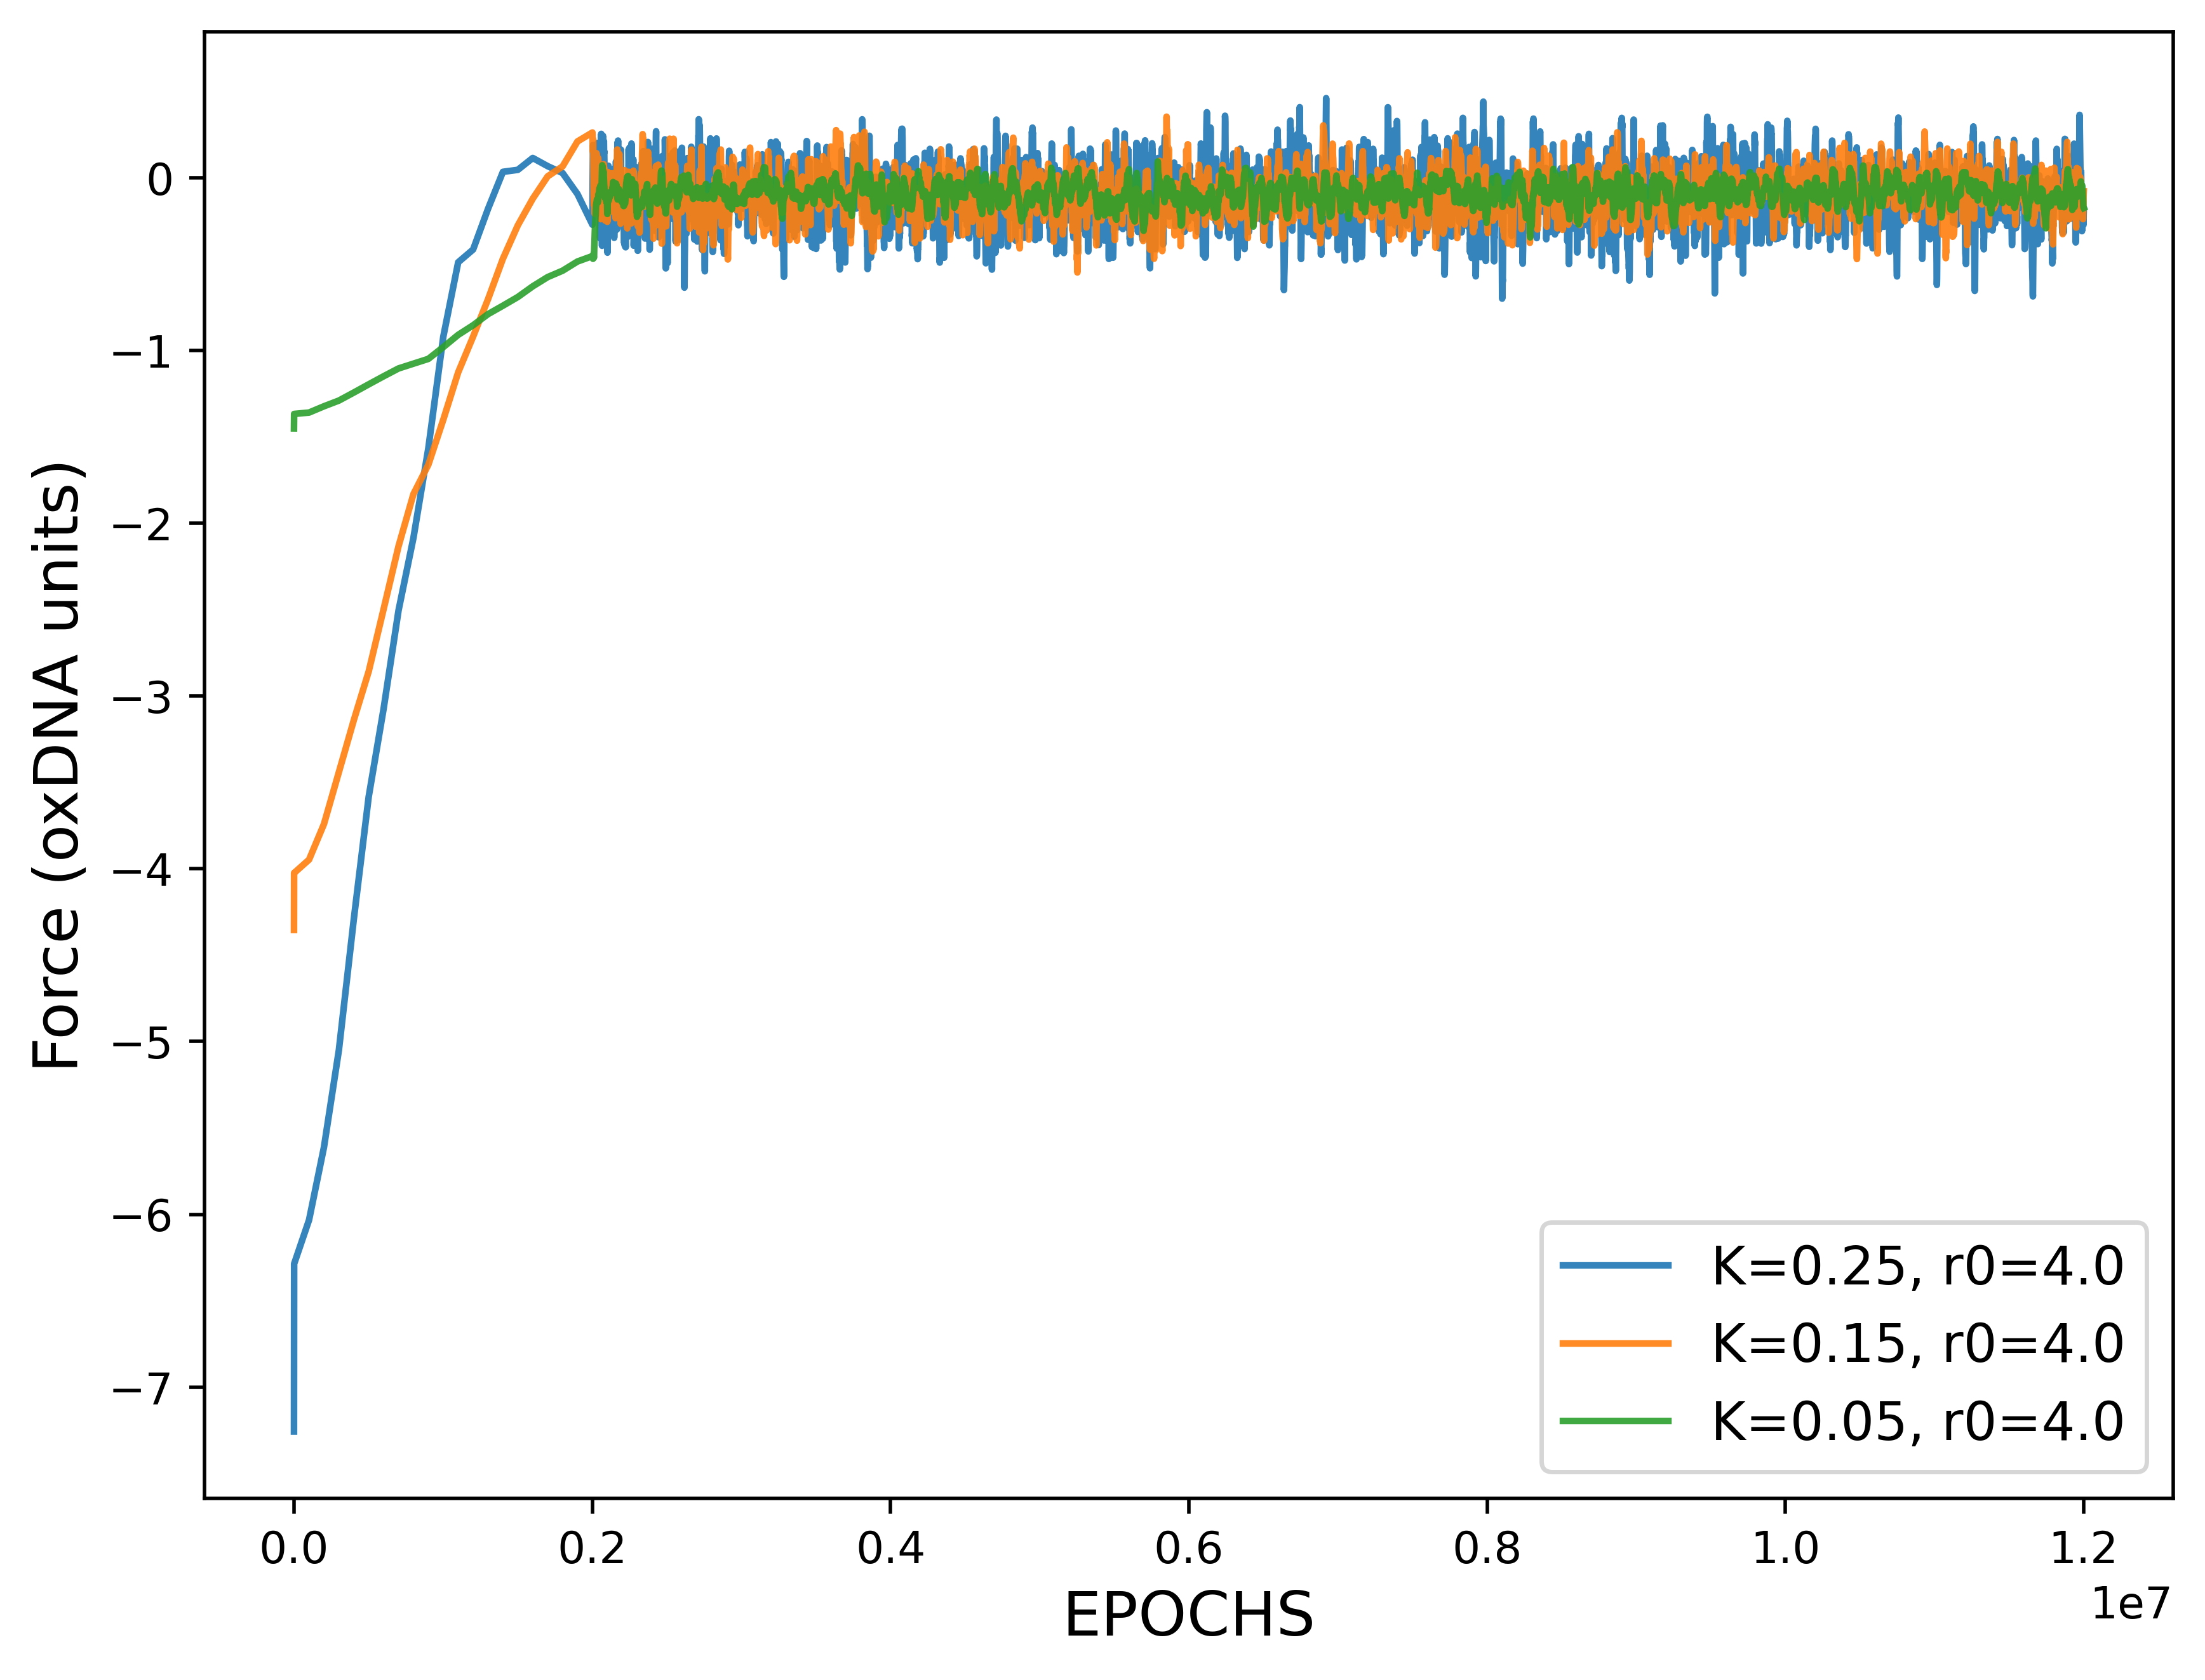

In [36]:
#### PLOT USING SELF-CALCULATED HOOKEAN PHYSICS
new_K05_r0_4_df_filtered = pd.DataFrame({
    'step': K05_r0_4_df_filtered['step'],
    'F': -0.05 * (K05_r0_4_df_filtered['dist']-4.0)
})
new_K15_r0_4_df_filtered = pd.DataFrame({
    'step': K15_r0_4_df_filtered['step'],
    'F': -0.15 * (K15_r0_4_df_filtered['dist']-4.0)
})
new_K25_r0_4_df_filtered = pd.DataFrame({
    'step': K25_r0_4_df_filtered['step'],
    'F': -0.25 * (K25_r0_4_df_filtered['dist']-4.0)
})

fig, ax = plt.subplots(figsize=(8,6), dpi=500)
ax.plot(new_K25_r0_4_df_filtered['step'], 
        new_K25_r0_4_df_filtered['F'], 
        alpha=0.9, linewidth=1.5, label='K=0.25, r0=4.0')
ax.plot(new_K15_r0_4_df_filtered['step'], 
        new_K15_r0_4_df_filtered['F'], 
        alpha=0.9, linewidth=1.5, label='K=0.15, r0=4.0')
ax.plot(new_K05_r0_4_df_filtered['step'], 
        new_K05_r0_4_df_filtered['F'], 
        alpha=0.9, linewidth=1.5, label='K=0.05, r0=4.0')
ax.set_xlabel('EPOCHS', fontsize=14)
ax.set_ylabel('Force (oxDNA units)', fontsize=14)
ax.legend(fontsize=12)

K15_r0_2_df_filtered: mean 0.14478236596007177 std 0.09488159475643916


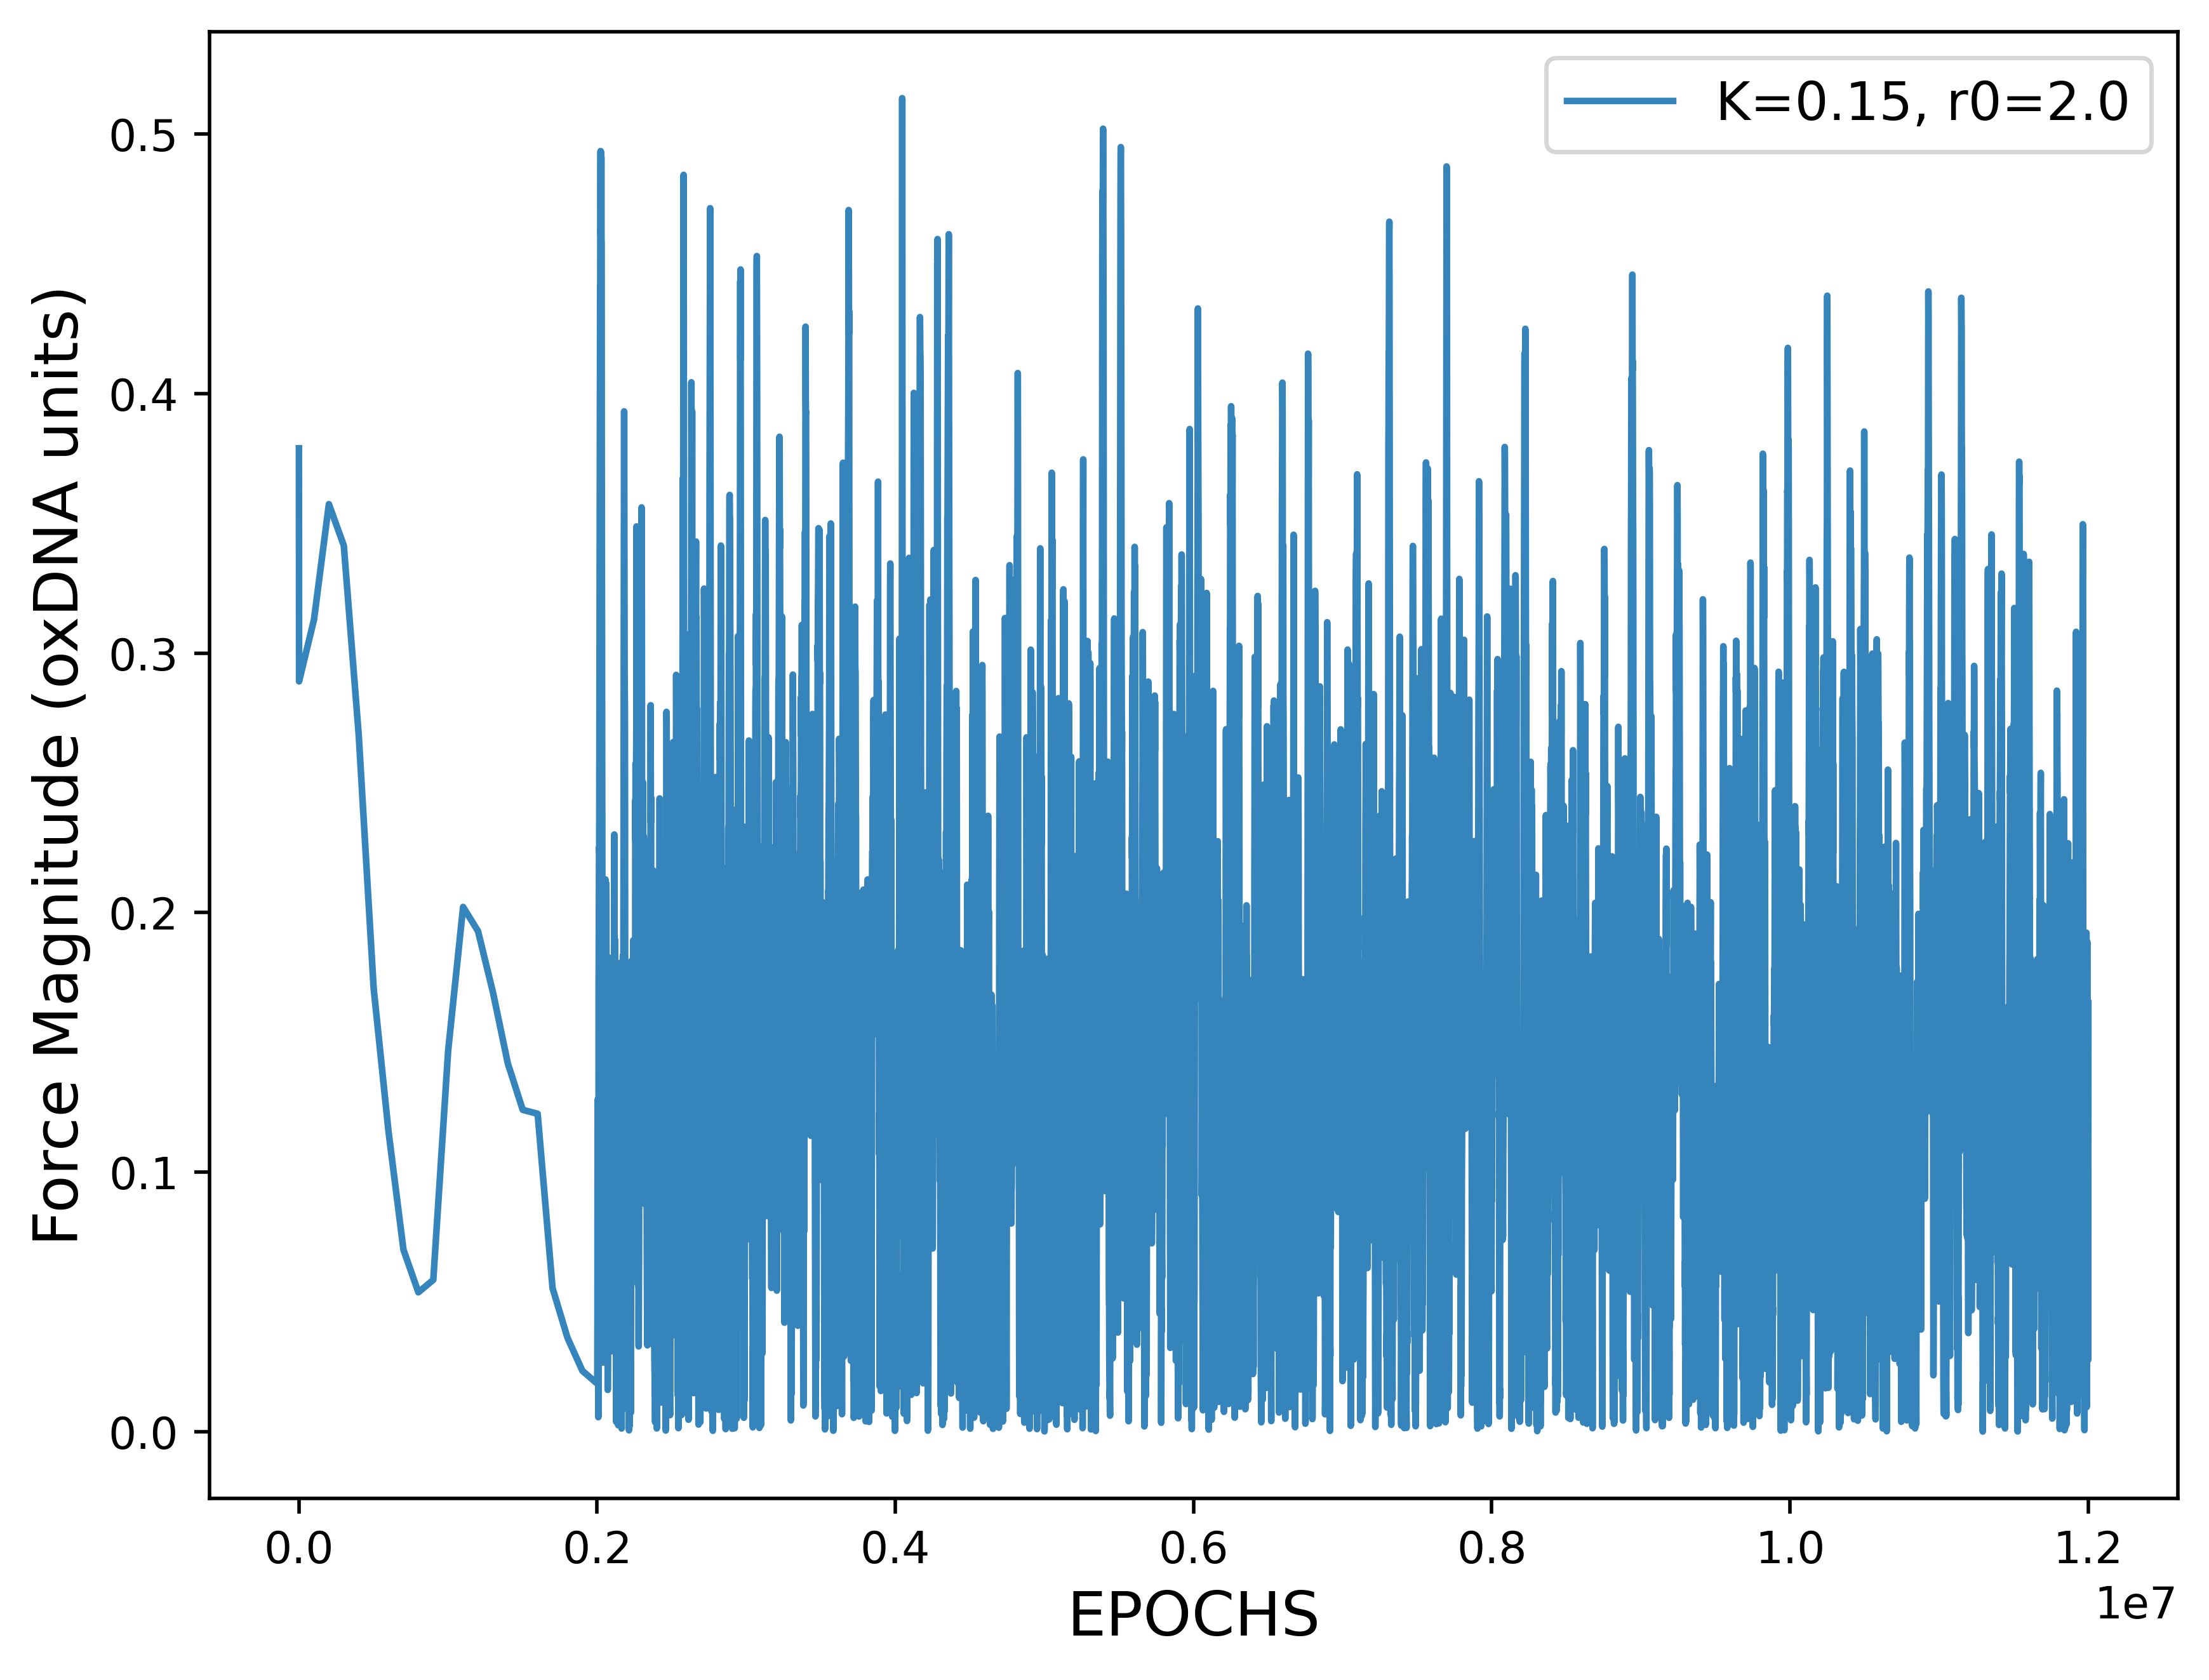

In [39]:
#### PLOT SIGNALS FOR R0=2.0
fig, ax = plt.subplots(figsize=(8,6), dpi=500)
ax.plot(K15_r0_2_df_filtered['step'],
        K15_r0_2_df_filtered['force_mag_filtered'],
        alpha=0.9, linewidth=1.5, label='K=0.15, r0=2.0')
ax.set_xlabel('EPOCHS', fontsize=14)
ax.set_ylabel('Force Magnitude (oxDNA units)', fontsize=14)
ax.legend(fontsize=12)

print("K15_r0_2_df_filtered:",
      "mean", np.mean(K15_r0_2_df_filtered['force_mag_filtered']),
      "std", np.std(K15_r0_2_df_filtered['force_mag_filtered']))